# Aula 12 — Laboratório: Matplotlib, Seaborn e Plotly (Prática) · Exercícios

**Unidade 3 — Análise Exploratória de Dados e Visualização** · ver também: [conteúdo](conteudo.ipynb) · [atividades](atividades.ipynb)

**💻 Exemplo Prático e Exercício — Gráficos com Matplotlib, Seaborn e Plotly (Aula 12)**

O pacote abaixo traz o laboratório guiado (Aula12_Visualizacao_Laboratorio.ipynb), com todas as saídas e gráficos: anatomia de uma figura, histograma com média e mediana, boxplot com quartis, IQR e outliers, violino, dispersão com r e reta de regressão, barras com IC 95% e *n*, mapa de calor da correlação, paletas, antes × depois, painel 2×2 e gráficos interativos no Plotly, usando 600 pedidos de uma hamburgueria fictícia. Traz também o exercício prático (Aula12_Exercicio_Pratico.ipynb), com 240 usuários de um app de música fictício: nove passos com o resultado esperado em cada um, e o gabarito comentado. O exercício é para treino e não precisa ser entregue.

---
## Pacote — Aula 12 (notebooks e datasets)

> Arquivo ZIP com o laboratório guiado (com saídas e gráficos), o exercício prático e seu gabarito, os dois datasets sintéticos (delivery da hamburgueria e app de música), o script gerador, as figuras exportadas e os gráficos interativos do Plotly em HTML. Extraia mantendo a pasta dados ao lado dos notebooks.

> Pacote `Aula12_Pacote_Notebooks_Dados.zip` extraído nesta pasta: `requirements.txt`, `LEIA-ME.md`, `Aula12_Exercicio_Pratico.ipynb`, `Aula12_Exercicio_Gabarito.ipynb`, `Aula12_Visualizacao_Laboratorio.ipynb`, `gerar_dados.py` e as pastas `dados/`, `figuras/`, `graficos/`.

## Pacote — Aula 12 (notebooks e datasets) — `Aula12_Visualizacao_Laboratorio.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

### Aula 12 — Laboratório: Matplotlib, Seaborn e Plotly

**Especialização em Ciência de Dados · Análise e Ciência de Dados · IFRN**
Unidade 3 — Análise Exploratória de Dados e Visualização (segunda aula)

Neste laboratório você vai construir, passo a passo, os gráficos mais usados na Análise Exploratória de Dados (AED) e aprender a **colocar no gráfico os números que sustentam a leitura**: média, mediana, quartis, IQR, coeficiente de correlação, intervalo de confiança e tamanho de amostra (*n*).

##### Caso da aula — Delivery da hamburgueria *Brasa & Pão* (fictícia)
600 pedidos entregues em 8 semanas. A gerência quer responder a três perguntas:

1. **Quanto tempo uma entrega costuma levar?** (gráficos univariados)
2. **O que faz a entrega demorar — distância, chuva, bairro, veículo?** (gráficos bivariados)
3. **Como apresentar isso em uma página para a gerência?** (customização, paletas e interatividade)

> Os dados são **sintéticos** (gerados por `gerar_dados.py`, semente fixa). Nenhum registro corresponde a pessoa ou empresa real.

##### Roteiro (1h30)

| Tempo | Parte | Gráficos | Estatísticas no gráfico |
|---|---|---|---|
| 0–10 min | 0. Preparação e anatomia de uma figura | linha | média de referência |
| 10–35 min | 1. Univariados | histograma, boxplot, violino | média, mediana, desvio-padrão, assimetria, quartis, IQR, outliers |
| 35–60 min | 2. Bivariados | dispersão, barras, mapa de calor | r de Pearson e Spearman, reta de regressão, média ± IC 95%, *n*, matriz de correlação |
| 60–75 min | 3. Customização e paletas | antes/depois, painel 2×2 | destaque, rótulos diretos, fonte |
| 75–90 min | 4. Plotly (interativo) e fechamento | histograma + boxplot marginal, dispersão, boxplot, mapa de calor | *hover* com os valores |

##### Dicionário de dados — `dados/delivery_hamburgueria.csv`

| Coluna | Tipo | Descrição |
|---|---|---|
| `pedido_id` | identificador | número do pedido |
| `data`, `dia_semana` | data / qualitativa ordinal | dia da entrega (Seg … Dom) |
| `turno` | qualitativa nominal | Almoço ou Jantar |
| `bairro` | qualitativa nominal | Centro, Jardim, Lagoa, Praia, Serra (do mais próximo ao mais distante) |
| `distancia_km` | quantitativa contínua | distância da loja até o cliente |
| `veiculo` | qualitativa nominal | Moto ou Bicicleta (bicicleta só faz entregas de até 3 km) |
| `chuva` | qualitativa nominal | choveu no dia? (Sim/Não) |
| `itens` | quantitativa discreta | itens no pedido |
| `valor_pedido` | quantitativa contínua | valor dos produtos (R$) |
| `taxa_entrega` | quantitativa contínua | taxa cobrada (R$) |
| `tempo_entrega_min` | quantitativa discreta | minutos entre o pedido e a entrega |
| `avaliacao` | qualitativa ordinal (1–5) | nota dada pelo cliente |

#### Parte 0 — Preparação

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats
from pathlib import Path

# Tema único para toda a aula: fundo branco com grade leve e paleta segura para daltônicos
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 12

# Plotly: funciona no Jupyter e no VS Code
pio.renderers.default = "plotly_mimetype+notebook_connected"

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)       # PNGs para relatório
HTML = Path("graficos"); HTML.mkdir(exist_ok=True)    # gráficos interativos

CORES = sns.color_palette("colorblind")
AZUL, LARANJA, VERDE, VERMELHO = CORES[0], CORES[1], CORES[2], CORES[3]
CINZA = "#8c8c8c"

def br(x, casas=1):
    """Formata número no padrão brasileiro: 1234.5 -> '1.234,5'."""
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [2]:
df = pd.read_csv("dados/delivery_hamburgueria.csv", parse_dates=["data"])

ORDEM_DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
ORDEM_BAIRROS = ["Centro", "Jardim", "Lagoa", "Praia", "Serra"]   # do mais perto ao mais longe
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=ORDEM_DIAS, ordered=True)

print(df.shape)
df.head()

(600, 13)


,pedido_id,data,dia_semana,turno,bairro,distancia_km,veiculo,chuva,itens,valor_pedido,taxa_entrega,tempo_entrega_min,avaliacao
0,1,2026-08-03,Seg,Almoço,Serra,6.6,Moto,Não,3,89.88,10.51,36,4
1,2,2026-08-03,Seg,Jantar,Serra,6.9,Moto,Não,3,73.78,10.41,39,3
2,3,2026-08-03,Seg,Almoço,Praia,7.7,Moto,Não,1,28.82,10.73,38,4
3,4,2026-08-03,Seg,Jantar,Serra,9.9,Moto,Não,2,66.48,12.61,46,4
4,5,2026-08-03,Seg,Almoço,Praia,6.3,Moto,Não,5,124.49,9.82,40,3


In [3]:
df.describe().round(2).T

,count,mean,min,25%,50%,75%,max,std
pedido_id,600.0,300.5,1.0,150.75,300.5,450.25,600.0,173.35
data,600,2026-08-30 22:07:12,2026-08-03 00:00:00,2026-08-16 00:00:00,2026-08-30 00:00:00,2026-09-16 00:00:00,2026-09-27 00:00:00,NaN
distancia_km,600.0,4.14,0.5,2.1,3.5,5.6,14.0,2.63
itens,600.0,3.74,1.0,3.0,4.0,5.0,10.0,1.61
valor_pedido,600.0,102.73,18.0,69.27,95.57,131.14,318.93,48.46
taxa_entrega,600.0,7.72,4.0,5.88,7.12,9.02,16.98,2.39
tempo_entrega_min,600.0,37.42,17.0,30.0,36.0,43.0,88.0,10.36
avaliacao,600.0,3.92,1.0,3.0,4.0,4.0,5.0,0.78


##### 0.1 Anatomia de uma figura no Matplotlib

Todo gráfico do Matplotlib (e, por baixo, do Seaborn) tem duas peças:

* **`Figure`** — a "folha" inteira (tamanho, título geral, `savefig`);
* **`Axes`** — cada área de plotagem, com seus eixos, título, rótulos e legenda.

Usaremos sempre a **interface orientada a objetos**: `fig, ax = plt.subplots(...)` e depois `ax.metodo(...)`. Ela deixa claro *em qual* gráfico cada comando atua — essencial quando a figura tem vários painéis. As funções do Seaborn recebem `ax=ax` e desenham dentro do `Axes` indicado.

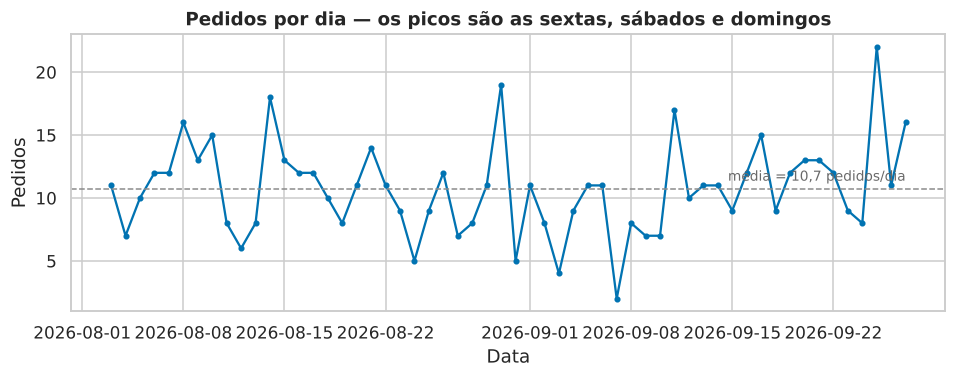

In [4]:
pedidos_dia = df.groupby("data").size()
media_dia = pedidos_dia.mean()

fig, ax = plt.subplots(figsize=(9, 3.6))                     # Figure + 1 Axes
ax.plot(pedidos_dia.index, pedidos_dia.values, marker="o", ms=3, lw=1.5, color=AZUL)
ax.axhline(media_dia, ls="--", lw=1, color=CINZA)             # linha de referência
ax.text(pedidos_dia.index[-1], media_dia + 0.4, f"média = {br(media_dia)} pedidos/dia",
        ha="right", va="bottom", color="dimgray", fontsize=9)
ax.set(title="Pedidos por dia — os picos são as sextas, sábados e domingos",
       xlabel="Data", ylabel="Pedidos")
fig.tight_layout()
plt.show()

#### Parte 1 — Gráficos univariados: *quanto tempo uma entrega costuma levar?*

Um gráfico univariado mostra a **distribuição** de uma única variável: onde está o centro, quanto os valores variam, se há assimetria e valores atípicos. Por isso, os números que acompanham esses gráficos são as **medidas da Aula 11**.

##### 1.1 Histograma — forma da distribuição + média e mediana

Primeiro calculamos as estatísticas; depois desenhamos e **escrevemos os valores no gráfico**.

In [5]:
t = df["tempo_entrega_min"]
resumo = pd.Series({
    "n": t.count(),
    "média": t.mean(),
    "mediana": t.median(),
    "desvio-padrão": t.std(),
    "assimetria (skew)": t.skew(),
    "mínimo": t.min(),
    "máximo": t.max(),
}).round(2)
resumo

n                    600.00
média                 37.42
mediana               36.00
desvio-padrão         10.36
assimetria (skew)      1.18
mínimo                17.00
máximo                88.00
dtype: float64

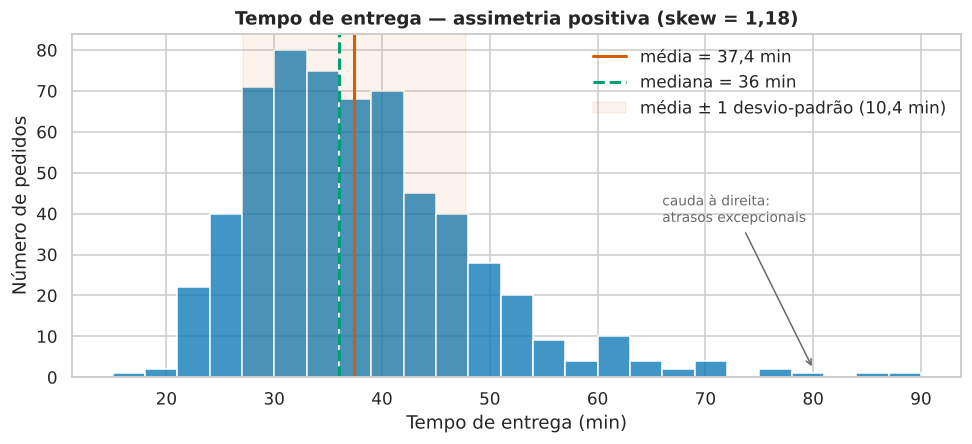

In [6]:
media, mediana, dp = t.mean(), t.median(), t.std()

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(t, bins=range(15, 92, 3), color=AZUL, alpha=0.75, edgecolor="white", ax=ax)
ax.axvline(media, color=VERMELHO, lw=2, label=f"média = {br(media)} min")
ax.axvline(mediana, color=VERDE, lw=2, ls="--", label=f"mediana = {br(mediana, 0)} min")
ax.axvspan(media - dp, media + dp, color=VERMELHO, alpha=0.07,
           label=f"média ± 1 desvio-padrão ({br(dp)} min)")
ax.annotate("cauda à direita:\natrasos excepcionais", xy=(80, 2), xytext=(66, 38),
            arrowprops=dict(arrowstyle="->", color="dimgray"), fontsize=9, color="dimgray")
ax.set(title=f"Tempo de entrega — assimetria positiva (skew = {br(t.skew(), 2)})",
       xlabel="Tempo de entrega (min)", ylabel="Número de pedidos")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "01_histograma.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura:** a média (37,4 min) fica **à direita** da mediana (36 min) porque poucos pedidos muito atrasados "puxam" a média — sinal de assimetria positiva. Para comunicar o "tempo típico", a **mediana** é mais robusta.

**A escolha do número de classes (`bins`) muda a história.** Poucas classes escondem detalhes; classes demais viram ruído. Comece com a regra padrão (`bins="auto"`) e ajuste olhando o resultado.

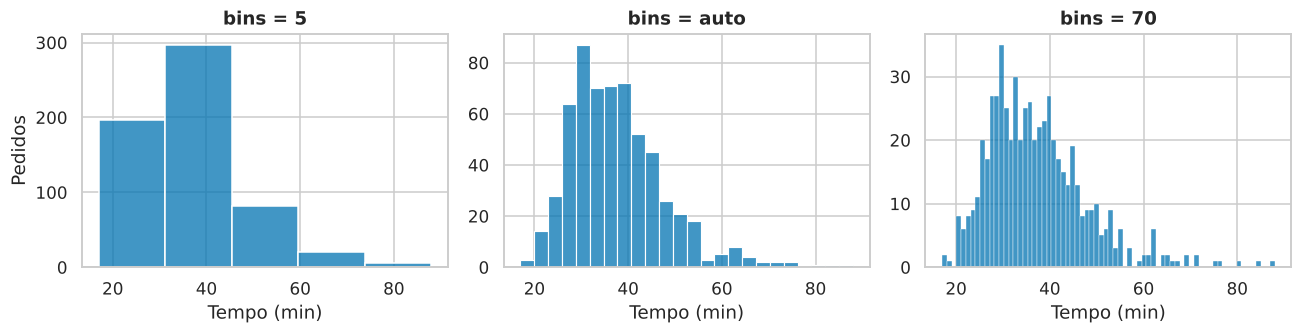

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for ax, b in zip(axes, [5, "auto", 70]):
    sns.histplot(t, bins=b, color=AZUL, edgecolor="white", ax=ax)
    ax.set(title=f"bins = {b}", xlabel="Tempo (min)", ylabel="")
axes[0].set_ylabel("Pedidos")
fig.tight_layout()
plt.show()

##### 1.2 Boxplot — quartis, IQR e outliers

O boxplot resume a distribuição em **cinco números** e marca os valores atípicos:

* caixa: do **Q1** (25%) ao **Q3** (75%) → altura = **IQR** (intervalo interquartil);
* linha dentro da caixa: **mediana** (Q2);
* "bigodes": vão até o último ponto dentro de **Q1 − 1,5·IQR** e **Q3 + 1,5·IQR**;
* pontos isolados: **outliers** pelo critério de Tukey.

In [8]:
q1, q2, q3 = t.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(t < lim_inf) | (t > lim_sup)]
print(f"Q1 = {q1:.0f} | mediana = {q2:.0f} | Q3 = {q3:.0f} | IQR = {iqr:.0f} min")
print(f"Limites de Tukey: [{lim_inf:.1f} ; {lim_sup:.1f}] min -> {len(outliers)} outliers")
outliers.sort_values("tempo_entrega_min", ascending=False).head(8)[
    ["pedido_id", "bairro", "distancia_km", "chuva", "tempo_entrega_min"]]

Q1 = 30 | mediana = 36 | Q3 = 43 | IQR = 13 min
Limites de Tukey: [10.5 ; 62.5] min -> 15 outliers


,pedido_id,bairro,distancia_km,chuva,tempo_entrega_min
536,537,Praia,9.4,Sim,88
365,366,Jardim,2.7,Não,84
216,217,Lagoa,7.9,Não,80
464,465,Jardim,2.4,Não,76
597,598,Jardim,3.3,Sim,75
312,313,Jardim,1.8,Sim,71
287,288,Serra,11.9,Sim,71
47,48,Serra,13.6,Não,69


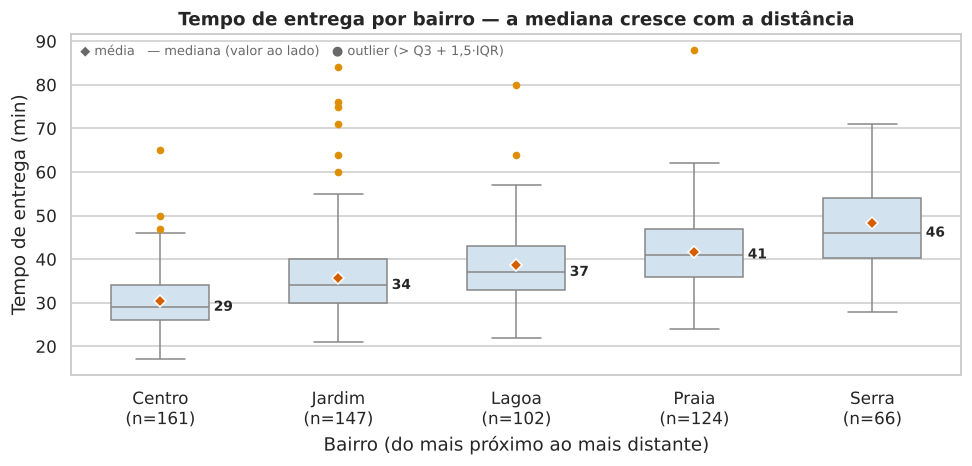

In [9]:
n_bairro = df["bairro"].value_counts()
med_bairro = df.groupby("bairro")["tempo_entrega_min"].median()

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.boxplot(data=df, x="bairro", y="tempo_entrega_min", order=ORDEM_BAIRROS,
            color="#cfe2f3", width=0.55, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor=VERMELHO, markeredgecolor="white", markersize=6),
            flierprops=dict(marker="o", markerfacecolor=LARANJA, markeredgecolor="none", markersize=5),
            ax=ax)
for i, b in enumerate(ORDEM_BAIRROS):
    ax.text(i + 0.30, med_bairro[b], f"{med_bairro[b]:.0f}", va="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(len(ORDEM_BAIRROS)),
              [f"{b}\n(n={n_bairro[b]})" for b in ORDEM_BAIRROS])
ax.set(title="Tempo de entrega por bairro — a mediana cresce com a distância",
       xlabel="Bairro (do mais próximo ao mais distante)", ylabel="Tempo de entrega (min)")
ax.text(0.01, 0.97, "◆ média   — mediana (valor ao lado)   ● outlier (> Q3 + 1,5·IQR)",
        transform=ax.transAxes, fontsize=8.5, color="dimgray", va="top")
fig.tight_layout()
fig.savefig(FIG / "02_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

##### 1.3 Violino — a forma completa da distribuição

O violino combina o boxplot com uma **estimativa de densidade (KDE)**: a largura mostra onde os valores se concentram. Com `inner="quart"`, as linhas internas são Q1, mediana e Q3. Com `split=True` comparamos dois grupos lado a lado.

In [10]:
tab = (df.groupby(["turno", "chuva"])["tempo_entrega_min"]
         .agg(n="size", mediana="median", media="mean").round(1))
tab

n  mediana  media
turno  chuva                     
Almoço Não    154     31.0   33.2
       Sim     54     39.0   39.9
Jantar Não    304     36.0   37.6
       Sim     88     40.5   42.6

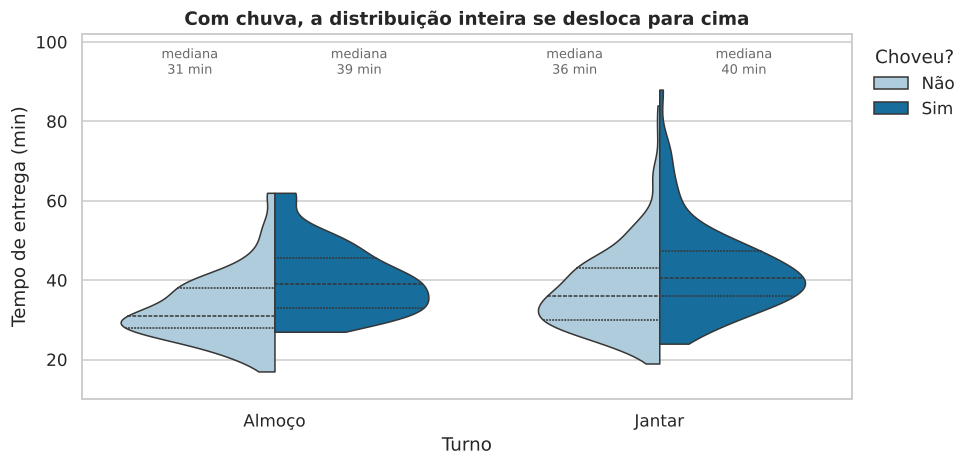

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.violinplot(data=df, x="turno", y="tempo_entrega_min", hue="chuva", hue_order=["Não", "Sim"],
               split=True, inner="quart", palette={"Não": "#a6cee3", "Sim": AZUL},
               cut=0, linewidth=1, ax=ax)
for i, turno in enumerate(["Almoço", "Jantar"]):
    for dx, ch in [(-0.22, "Não"), (0.22, "Sim")]:
        m = tab.loc[(turno, ch), "mediana"]
        ax.text(i + dx, 92, f"mediana\n{m:.0f} min", ha="center", fontsize=8.5, color="dimgray")
ax.set_ylim(10, 102)
ax.set(title="Com chuva, a distribuição inteira se desloca para cima",
       xlabel="Turno", ylabel="Tempo de entrega (min)")
ax.legend(title="Choveu?", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIG / "03_violino.png", dpi=200, bbox_inches="tight")
plt.show()

**Boxplot, violino ou pontos?** O boxplot **esconde o tamanho da amostra**: 111 entregas de bicicleta e 489 de moto viram caixas iguais. Sobrepor os pontos (`stripplot`) resolve isso.

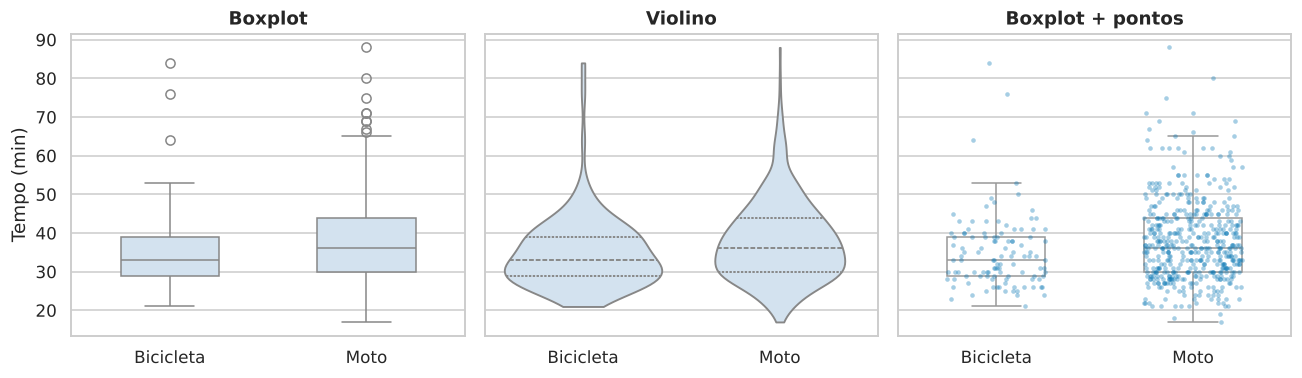

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
kw = dict(data=df, x="veiculo", y="tempo_entrega_min", order=["Bicicleta", "Moto"])
sns.boxplot(**kw, color="#cfe2f3", width=0.5, ax=axes[0])
sns.violinplot(**kw, color="#cfe2f3", inner="quart", cut=0, ax=axes[1])
sns.boxplot(**kw, color="white", width=0.5, showfliers=False, ax=axes[2])
sns.stripplot(**kw, color=AZUL, alpha=0.35, size=3, jitter=0.25, ax=axes[2])
for ax, nome in zip(axes, ["Boxplot", "Violino", "Boxplot + pontos"]):
    ax.set(title=nome, xlabel="", ylabel="")
axes[0].set_ylabel("Tempo (min)")
fig.tight_layout()
plt.show()

#### Parte 2 — Gráficos bivariados: *o que faz a entrega demorar?*

Agora cruzamos **duas variáveis**. A estatística que acompanha cada gráfico depende dos tipos envolvidos:

| Variáveis | Gráfico | Estatística no gráfico |
|---|---|---|
| numérica × numérica | dispersão (*scatter*) | r de Pearson / Spearman, reta de regressão |
| categórica × numérica | barras, boxplot, violino | média ± IC 95% (ou mediana e IQR), *n* por grupo |
| várias numéricas | mapa de calor da correlação | matriz de r |
| categórica × categórica (× numérica) | mapa de calor de tabela dinâmica | contagem ou média por célula |

##### 2.1 Dispersão — distância × tempo, com r e reta de regressão

In [13]:
x, y = df["distancia_km"], df["tempo_entrega_min"]
r_p, p_p = stats.pearsonr(x, y)
r_s, p_s = stats.spearmanr(x, y)
reg = stats.linregress(x, y)
print(f"Pearson r = {r_p:.2f} (p = {p_p:.1e}) | Spearman ρ = {r_s:.2f}")
print(f"Reta: tempo = {reg.intercept:.1f} + {reg.slope:.2f} × distância   (R² = {reg.rvalue**2:.2f})")

Pearson r = 0.71 (p = 4.2e-94) | Spearman ρ = 0.72
Reta: tempo = 25.8 + 2.80 × distância   (R² = 0.51)


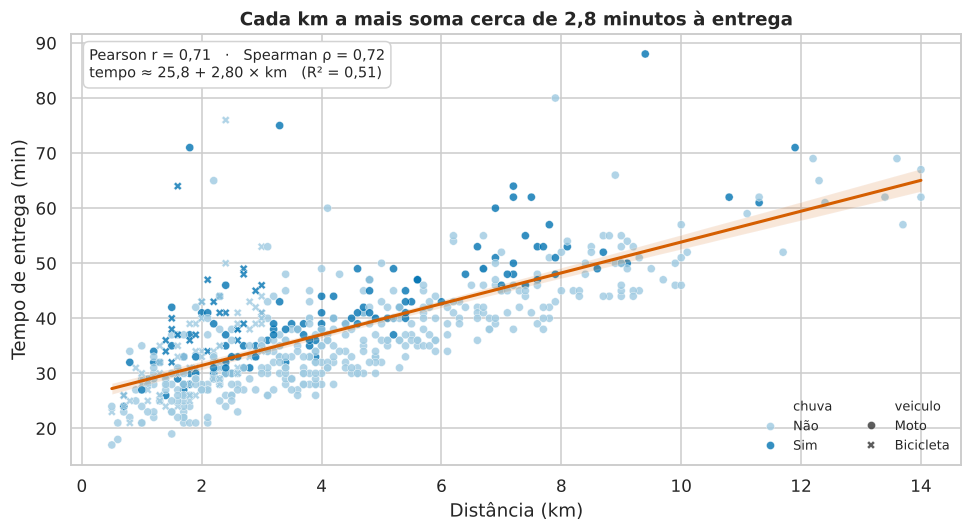

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="distancia_km", y="tempo_entrega_min", hue="chuva", hue_order=["Não", "Sim"],
                style="veiculo", palette={"Não": "#9ecae1", "Sim": AZUL}, s=28, alpha=0.8,
                edgecolor="white", linewidth=0.3, ax=ax)
sns.regplot(data=df, x="distancia_km", y="tempo_entrega_min", scatter=False,
            color=VERMELHO, line_kws=dict(lw=2), ax=ax)          # faixa = IC 95% da reta
ax.text(0.02, 0.97,
        f"Pearson r = {br(r_p, 2)}   ·   Spearman ρ = {br(r_s, 2)}\n"
        f"tempo ≈ {br(reg.intercept)} + {br(reg.slope, 2)} × km   (R² = {br(reg.rvalue**2, 2)})",
        transform=ax.transAxes, va="top", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="lightgray"))
ax.set(title=f"Cada km a mais soma cerca de {br(reg.slope)} minutos à entrega",
       xlabel="Distância (km)", ylabel="Tempo de entrega (min)")
ax.legend(frameon=False, loc="lower right", ncols=2, fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG / "04_dispersao.png", dpi=200, bbox_inches="tight")
plt.show()

**Pergunta de investigação:** *a bicicleta é mais rápida que a moto?* No boxplot anterior, a mediana da bicicleta é menor. Mas a bicicleta **só faz entregas curtas**. Compare apenas entregas de até 3 km:

In [15]:
curtas = df[df["distancia_km"] <= 3]
comparacao = pd.DataFrame({
    "todas as entregas": df.groupby("veiculo")["tempo_entrega_min"].median(),
    "só até 3 km": curtas.groupby("veiculo")["tempo_entrega_min"].median(),
    "n (até 3 km)": curtas["veiculo"].value_counts(),
})
comparacao

,todas as entregas,só até 3 km,n (até 3 km)
veiculo,,,
Bicicleta,33.0,33.0,111
Moto,36.0,29.0,148


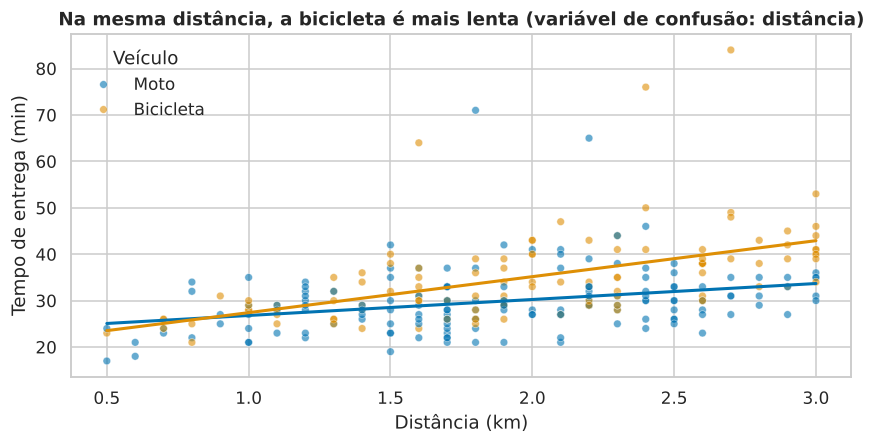

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.scatterplot(data=curtas, x="distancia_km", y="tempo_entrega_min", hue="veiculo",
                hue_order=["Moto", "Bicicleta"], palette=[AZUL, LARANJA], alpha=0.6, s=25, ax=ax)
for veic, cor in [("Moto", AZUL), ("Bicicleta", LARANJA)]:
    sns.regplot(data=curtas[curtas["veiculo"] == veic], x="distancia_km", y="tempo_entrega_min",
                scatter=False, ci=None, color=cor, line_kws=dict(lw=2), ax=ax)
ax.set(title="Na mesma distância, a bicicleta é mais lenta (variável de confusão: distância)",
       xlabel="Distância (km)", ylabel="Tempo de entrega (min)")
ax.legend(title="Veículo", frameon=False)
fig.tight_layout()
plt.show()

##### 2.2 Gráfico de barras — média com intervalo de confiança e *n*

No Seaborn, `barplot` **calcula uma estatística** (média, por padrão) e desenha uma barra de erro. Deixe explícito qual é:

* `errorbar=("ci", 95)` → intervalo de confiança de 95% da média (*bootstrap*) — **padrão**;
* `errorbar="sd"` → média ± 1 desvio-padrão (dispersão dos dados);
* `errorbar="se"` → erro-padrão; `estimator="median"` troca a média pela mediana.

Já `countplot` apenas **conta** linhas por categoria.

In [17]:
valor_dia = df.groupby("dia_semana", observed=True)["valor_pedido"].agg(n="size", media="mean").round(1)
valor_dia

,n,media
dia_semana,,
Seg,74,89.3
Ter,74,89.5
Qua,72,100.4
Qui,72,90.6
Sex,109,110.5
Sáb,95,118.5
Dom,104,109.2


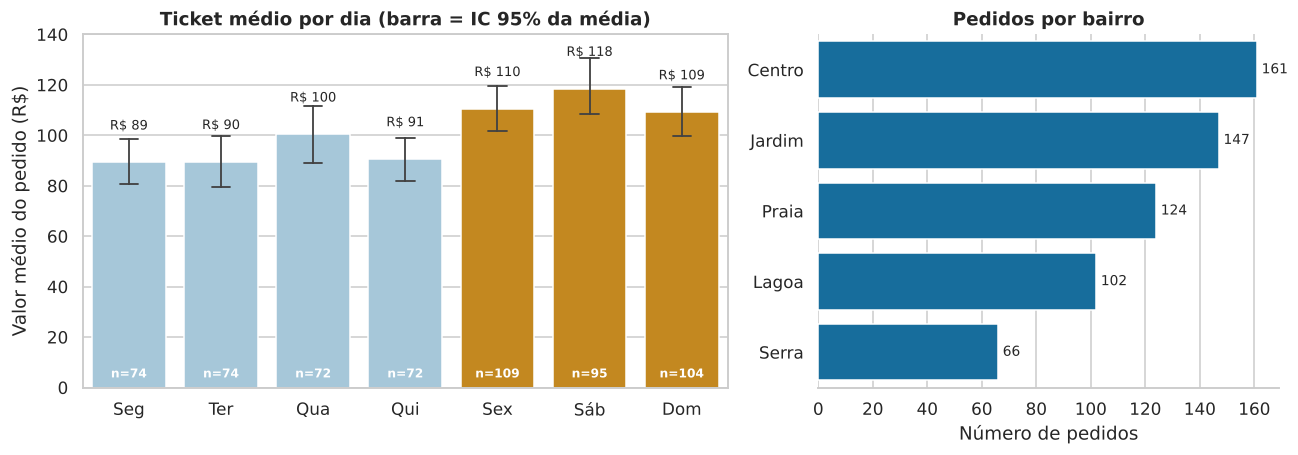

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw=dict(width_ratios=[1.4, 1]))

# (a) média do valor por dia + IC 95% + n
cores_dia = [LARANJA if d in ("Sex", "Sáb", "Dom") else "#9ecae1" for d in ORDEM_DIAS]
sns.barplot(data=df, x="dia_semana", y="valor_pedido", order=ORDEM_DIAS, hue="dia_semana",
            palette=cores_dia, legend=False, dodge=False, errorbar=("ci", 95), capsize=0.2,
            err_kws=dict(linewidth=1.2), seed=12, ax=axes[0])
for i, d in enumerate(ORDEM_DIAS):
    axes[0].text(i, 4, f"n={valor_dia.loc[d, 'n']}", ha="center", fontsize=8, color="white", fontweight="bold")
    axes[0].text(i, valor_dia.loc[d, "media"] + 13, f"R$ {br(valor_dia.loc[d, 'media'], 0)}",
                 ha="center", fontsize=8.5)
axes[0].set(title="Ticket médio por dia (barra = IC 95% da média)",
            xlabel="", ylabel="Valor médio do pedido (R$)", ylim=(0, 140))

# (b) contagem de pedidos por bairro, ordenada
ordem_qtd = df["bairro"].value_counts().index
sns.countplot(data=df, y="bairro", order=ordem_qtd, color=AZUL, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=9)
axes[1].set(title="Pedidos por bairro", xlabel="Número de pedidos", ylabel="")
sns.despine(ax=axes[1], left=True)
fig.tight_layout()
fig.savefig(FIG / "05_barras.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura:** de sexta a domingo o ticket médio sobe (pedidos com mais itens). Os intervalos de sexta/sábado/domingo quase não se sobrepõem aos de segunda/terça — indício de diferença real, que um teste estatístico confirmaria.

⚠️ Barras devem **começar no zero** (o comprimento da barra codifica o valor). Para mostrar a *distribuição* dentro de cada dia, use boxplot ou violino.

##### 2.3 Mapa de calor da correlação

A matriz de correlação resume, de uma vez, as relações lineares entre **todas** as variáveis numéricas. Boas práticas:

* paleta **divergente** centrada no zero (`center=0`, `vmin=-1`, `vmax=1`): azul = negativa, vermelho = positiva, branco = nula;
* `annot=True` para escrever o r em cada célula;
* máscara do triângulo superior (a matriz é simétrica).

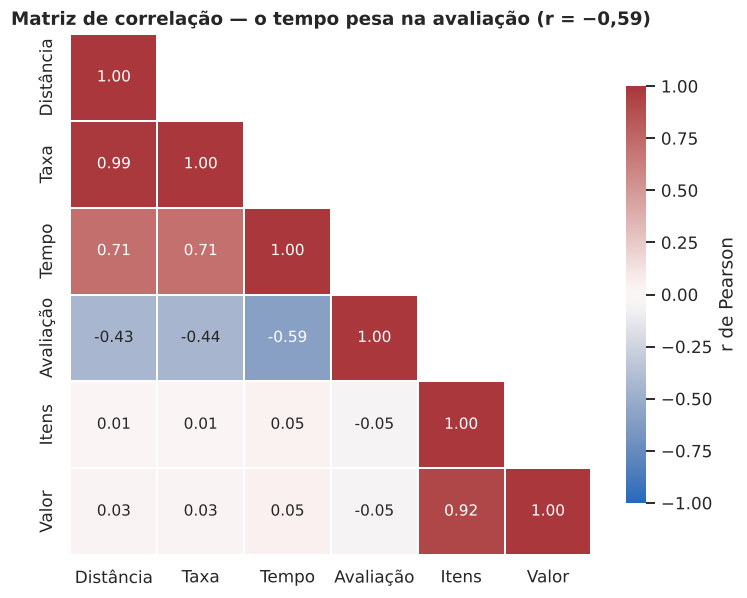

In [19]:
num = ["distancia_km", "taxa_entrega", "tempo_entrega_min", "avaliacao", "itens", "valor_pedido"]
rotulos = ["Distância", "Taxa", "Tempo", "Avaliação", "Itens", "Valor"]
corr = df[num].corr(method="pearson")
corr.index = corr.columns = rotulos
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white",
            cbar_kws=dict(label="r de Pearson", shrink=0.8), annot_kws=dict(size=10), ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação — o tempo pesa na avaliação (r = −0,59)")
fig.tight_layout()
fig.savefig(FIG / "06_heatmap_correlacao.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura:**
* **Distância × taxa (0,99):** a taxa é calculada a partir da distância — informação redundante.
* **Distância × tempo (0,71)** e **tempo × avaliação (−0,59):** a cadeia "longe → demora → nota baixa".
* **Itens × valor (0,92)** e quase nenhuma relação com tempo (≈ 0,05).

Um mapa de calor também serve para **tabelas dinâmicas** (categoria × categoria). Aqui a paleta é **sequencial** (uma cor, do claro ao escuro), porque os valores só crescem:

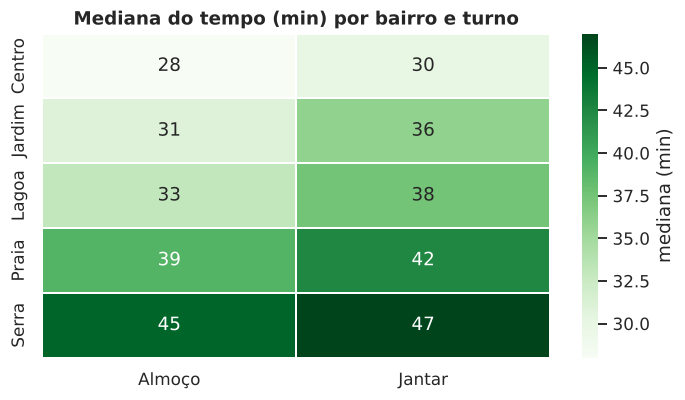

turno,Almoço,Jantar,Δ Jantar−Almoço
bairro,,,
Centro,28.0,30.0,2.0
Jardim,31.0,36.0,5.0
Lagoa,33.0,37.5,4.5
Praia,39.0,42.5,3.5
Serra,45.0,47.0,2.0


In [20]:
pivo = df.pivot_table(index="bairro", columns="turno", values="tempo_entrega_min",
                      aggfunc="median").loc[ORDEM_BAIRROS]
pivo["Δ Jantar−Almoço"] = pivo["Jantar"] - pivo["Almoço"]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(pivo[["Almoço", "Jantar"]], annot=True, fmt=".0f", cmap="Greens",
            linewidths=1, cbar_kws=dict(label="mediana (min)"), ax=ax)
ax.grid(False)
ax.set(title="Mediana do tempo (min) por bairro e turno", xlabel="", ylabel="")
fig.tight_layout()
plt.show()
pivo

#### Parte 3 — Customização e paletas de cores

##### 3.1 Três tipos de paleta — escolha pelo **tipo de dado**

| Tipo | Quando usar | Exemplos no Seaborn/Matplotlib |
|---|---|---|
| **Qualitativa** (categórica) | categorias sem ordem (bairro, veículo) | `"colorblind"`, `"Set2"`, `"tab10"` |
| **Sequencial** | valores que só crescem (contagem, tempo) | `"viridis"`, `"Greens"`, `"rocket"` |
| **Divergente** | valores com um ponto central (correlação, variação) | `"vlag"`, `"RdBu"`, `"coolwarm"` |

Evite o arco-íris (`"jet"`): cria fronteiras falsas e não funciona para daltônicos nem em impressão em preto e branco.

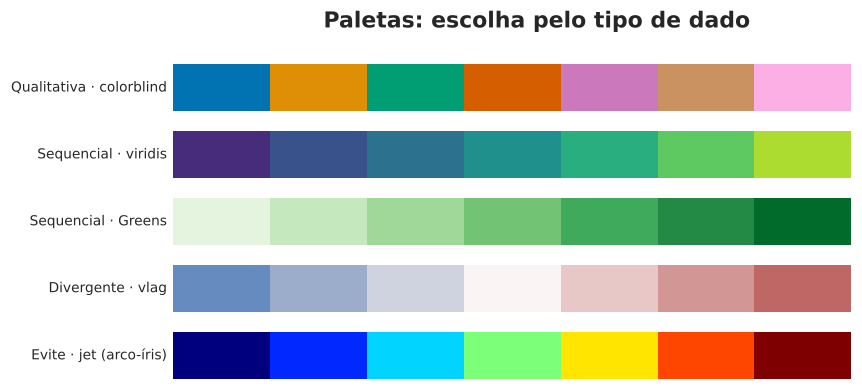

In [21]:
paletas = [("Qualitativa · colorblind", sns.color_palette("colorblind", 7)),
           ("Sequencial · viridis", sns.color_palette("viridis", 7)),
           ("Sequencial · Greens", sns.color_palette("Greens", 7)),
           ("Divergente · vlag", sns.color_palette("vlag", 7)),
           ("Evite · jet (arco-íris)", [plt.get_cmap("jet")(v) for v in np.linspace(0, 1, 7)])]
fig, axes = plt.subplots(len(paletas), 1, figsize=(8, 3.6))
for ax, (nome, pal) in zip(axes, paletas):
    ax.imshow([list(range(len(pal)))], cmap=plt.matplotlib.colors.ListedColormap(pal), aspect="auto")
    ax.set_yticks([]); ax.set_xticks([])
    ax.set_ylabel(nome, rotation=0, ha="right", va="center", fontsize=9)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("Paletas: escolha pelo tipo de dado", fontweight="bold", x=0.62)
fig.tight_layout()
fig.savefig(FIG / "07_paletas.png", dpi=200, bbox_inches="tight")
plt.show()

##### 3.2 Antes × depois — do gráfico padrão ao gráfico que comunica

Customizar é **tirar o que não ajuda** e **destacar o que importa**: ordenar, rotular diretamente, usar uma cor de destaque e escrever no título a conclusão.

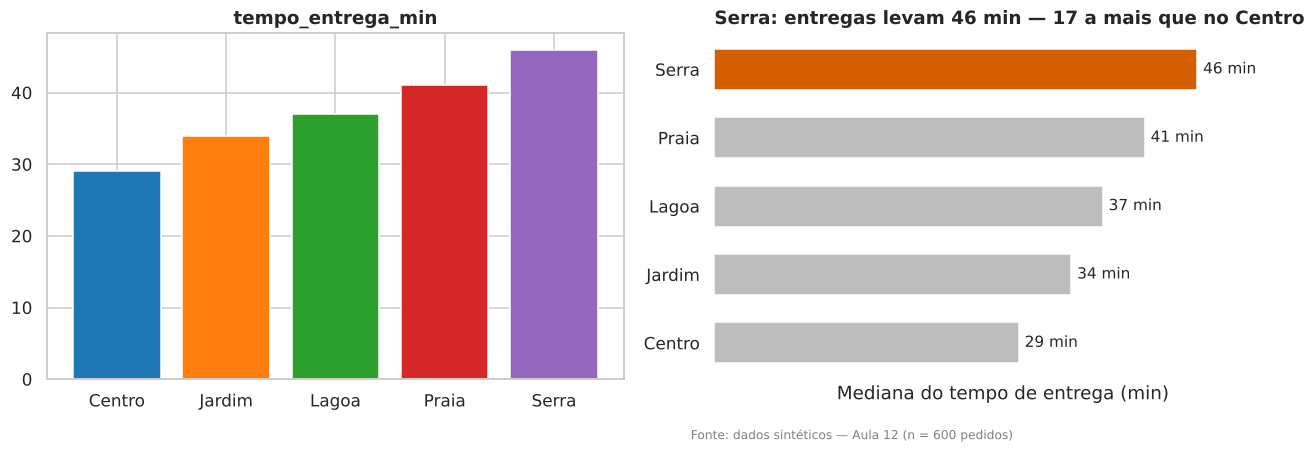

In [22]:
med = df.groupby("bairro")["tempo_entrega_min"].median().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# ANTES: padrão, ordem alfabética, cores sem significado, sem unidade
axes[0].bar(sorted(med.index), med.sort_index().values, color=sns.color_palette("tab10", 5))
axes[0].set_title("tempo_entrega_min")

# DEPOIS: ordenado, uma cor de destaque, rótulos diretos, título com a mensagem
cores = [VERMELHO if b == "Serra" else "#bdbdbd" for b in med.index]
barras = axes[1].barh(med.index, med.values, color=cores, height=0.6)
axes[1].bar_label(barras, labels=[f"{v:.0f} min" for v in med.values], padding=4, fontsize=10)
axes[1].set_title("Serra: entregas levam 46 min — 17 a mais que no Centro", loc="left")
axes[1].set_xlabel("Mediana do tempo de entrega (min)")
axes[1].set_xlim(0, 55)
axes[1].grid(False)
sns.despine(ax=axes[1], left=True, bottom=True)
axes[1].set_xticks([])
fig.text(0.53, -0.02, "Fonte: dados sintéticos — Aula 12 (n = 600 pedidos)", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig(FIG / "08_antes_depois.png", dpi=200, bbox_inches="tight")
plt.show()

##### 3.3 Painel 2×2 para a gerência (figura estática para relatório)

`plt.subplots(2, 2)` cria a grade; `fig.suptitle` dá o título geral; `savefig(dpi=200, bbox_inches="tight")` exporta em alta resolução sem cortar rótulos.

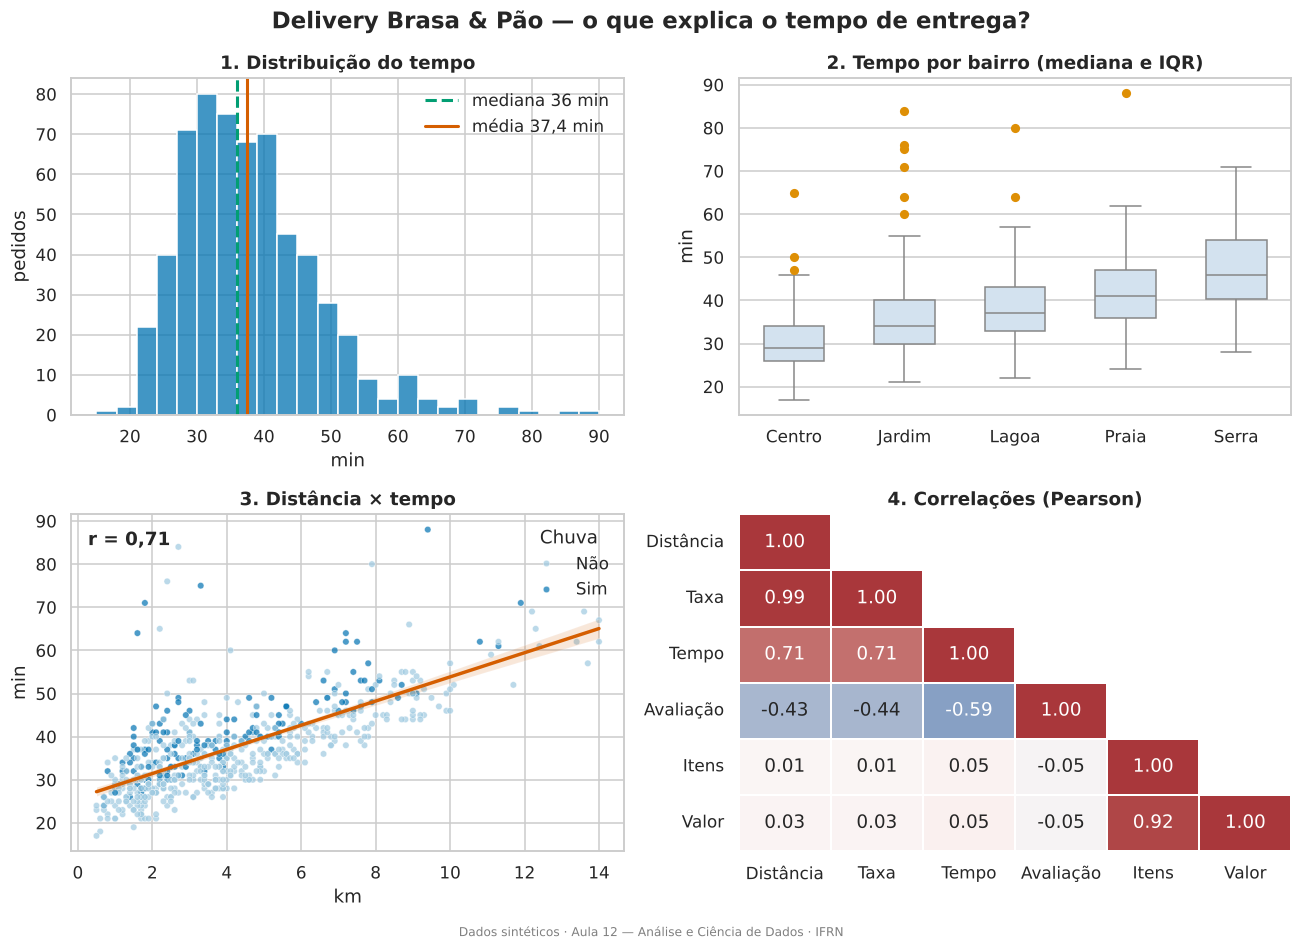

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
(a, b), (c, d) = axes

sns.histplot(t, bins=range(15, 92, 3), color=AZUL, edgecolor="white", ax=a)
a.axvline(mediana, color=VERDE, ls="--", lw=2, label=f"mediana {mediana:.0f} min")
a.axvline(media, color=VERMELHO, lw=2, label=f"média {br(media)} min")
a.legend(frameon=False); a.set(title="1. Distribuição do tempo", xlabel="min", ylabel="pedidos")

sns.boxplot(data=df, x="bairro", y="tempo_entrega_min", order=ORDEM_BAIRROS, color="#cfe2f3",
            width=0.55, flierprops=dict(markerfacecolor=LARANJA, markeredgecolor="none"), ax=b)
b.set(title="2. Tempo por bairro (mediana e IQR)", xlabel="", ylabel="min")

sns.scatterplot(data=df, x="distancia_km", y="tempo_entrega_min", hue="chuva", hue_order=["Não", "Sim"],
                palette={"Não": "#9ecae1", "Sim": AZUL}, s=18, alpha=0.7, ax=c)
sns.regplot(data=df, x="distancia_km", y="tempo_entrega_min", scatter=False, color=VERMELHO, ax=c)
c.text(0.03, 0.95, f"r = {br(r_p, 2)}", transform=c.transAxes, va="top", fontweight="bold")
c.set(title="3. Distância × tempo", xlabel="km", ylabel="min"); c.legend(title="Chuva", frameon=False)

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            linewidths=1, cbar=False, ax=d)
d.grid(False); d.set_title("4. Correlações (Pearson)")

fig.suptitle("Delivery Brasa & Pão — o que explica o tempo de entrega?", fontsize=15, fontweight="bold")
fig.text(0.5, -0.01, "Dados sintéticos · Aula 12 — Análise e Ciência de Dados · IFRN",
         ha="center", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig(FIG / "09_painel_gerencia.png", dpi=200, bbox_inches="tight")
plt.show()

#### Parte 4 — Plotly: gráficos interativos

O **Plotly Express** (`px`) faz em uma linha os mesmos gráficos, com **interatividade**: passar o mouse mostra os valores (*hover*), dá para dar zoom, filtrar pela legenda e exportar para HTML. É ideal para explorar e para compartilhar com quem não roda Python.

##### 4.1 Histograma com boxplot marginal

In [24]:
fig = px.histogram(df, x="tempo_entrega_min", nbins=30, marginal="box",
                   color_discrete_sequence=["#0173b2"],
                   labels={"tempo_entrega_min": "Tempo de entrega (min)"},
                   title="Tempo de entrega — histograma com boxplot marginal")
fig.add_vline(x=media, line_color="#d55e00", annotation_text=f"média {br(media)}", row=1, col=1)
fig.add_vline(x=mediana, line_dash="dash", line_color="#029e73",
              annotation_text=f"mediana {mediana:.0f}", annotation_position="top left", row=1, col=1)
fig.update_layout(template="plotly_white", bargap=0.05, yaxis_title="Pedidos")
fig.show()

##### 4.2 Dispersão com *hover* detalhado e reta de regressão

In [25]:
xs = np.linspace(x.min(), x.max(), 50)
fig = px.scatter(df, x="distancia_km", y="tempo_entrega_min", color="chuva", symbol="veiculo",
                 hover_data=["pedido_id", "bairro", "turno", "valor_pedido", "avaliacao"],
                 color_discrete_map={"Não": "#9ecae1", "Sim": "#0173b2"}, opacity=0.8,
                 labels={"distancia_km": "Distância (km)", "tempo_entrega_min": "Tempo (min)",
                         "chuva": "Chuva", "veiculo": "Veículo"},
                 title=f"Distância × tempo (r de Pearson = {br(r_p, 2)})")
fig.add_trace(go.Scatter(x=xs, y=reg.intercept + reg.slope * xs, mode="lines",
                         line=dict(color="#d55e00", width=3), name="reta de regressão"))
fig.update_layout(template="plotly_white")
fig.write_html(HTML / "dispersao_interativa.html", include_plotlyjs="cdn")
fig.show()

##### 4.3 Boxplot e violino interativos (o *hover* mostra Q1, mediana, Q3 e cercas)

In [26]:
fig = px.box(df, x="bairro", y="tempo_entrega_min", color="chuva", points="outliers",
             category_orders={"bairro": ORDEM_BAIRROS, "chuva": ["Não", "Sim"]},
             color_discrete_map={"Não": "#9ecae1", "Sim": "#0173b2"},
             labels={"tempo_entrega_min": "Tempo (min)", "bairro": "Bairro", "chuva": "Chuva"},
             title="Tempo de entrega por bairro e chuva")
fig.update_layout(template="plotly_white")
fig.write_html(HTML / "boxplot_interativo.html", include_plotlyjs="cdn")
fig.show()

In [27]:
fig = px.violin(df, x="turno", y="tempo_entrega_min", color="chuva", box=True,
                color_discrete_map={"Não": "#9ecae1", "Sim": "#0173b2"},
                labels={"tempo_entrega_min": "Tempo (min)", "turno": "Turno", "chuva": "Chuva"},
                title="Violino por turno e chuva (com boxplot interno)")
fig.update_layout(template="plotly_white", violinmode="group")
fig.show()

##### 4.4 Mapa de calor interativo da correlação

In [28]:
fig = px.imshow(corr.round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Matriz de correlação (Pearson)")
fig.update_layout(template="plotly_white", width=600, height=520)
fig.write_html(HTML / "heatmap_interativo.html", include_plotlyjs="cdn")
fig.show()

#### Fechamento — o que levar desta aula

**Qual gráfico usar?**

| Pergunta | Gráfico | Mostre também |
|---|---|---|
| Como uma variável numérica se distribui? | histograma | média, mediana, (desvio-padrão, assimetria) |
| Há outliers? Como grupos se comparam? | boxplot | mediana, IQR, *n* por grupo |
| Qual a forma da distribuição em cada grupo? | violino | quartis (`inner="quart"`) |
| Duas numéricas se relacionam? | dispersão | r de Pearson/Spearman, reta de regressão |
| Qual a média/contagem por categoria? | barras | IC 95% ou desvio-padrão (diga qual!), *n* |
| Como várias numéricas se relacionam? | mapa de calor | r em cada célula, escala −1 a 1 |

**Checklist de um bom gráfico**
1. O título diz **a conclusão**, não só o nome da variável.
2. Eixos com nome **e unidade** (min, km, R$).
3. A estatística mostrada está **identificada** (média? mediana? IC 95%? sd?).
4. O tamanho da amostra (*n*) aparece quando você compara grupos.
5. Paleta adequada ao tipo de dado e segura para daltônicos; cor com **significado**.
6. Barras começam no zero; nada de 3D, pizza com muitas fatias ou dois eixos y.
7. Fonte dos dados no rodapé.

**Para praticar:** abra `Aula12_Exercicio_Pratico.ipynb` (usuários de um app de música fictício). O exercício é para treino e **não precisa ser entregue**.

## Pacote — Aula 12 (notebooks e datasets) — `Aula12_Exercicio_Pratico.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

### Aula 12 — Exercício prático: usuários de um app de música (sem entrega)

**Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN**

Um aplicativo de música **fictício** quer entender como seus 240 usuários usam o serviço. Você vai aplicar o roteiro do laboratório: **univariados → bivariados → customização → Plotly**, sempre colocando no gráfico a estatística que sustenta a leitura.

> Dados **sintéticos** (`gerar_dados.py`, semente fixa). Nenhum registro é real. O exercício é para treino e **não precisa ser entregue**. Cada passo traz o **resultado esperado** para você conferir. O gabarito comentado está em `Aula12_Exercicio_Gabarito.ipynb` — tente antes de olhar!

| Coluna | Descrição |
|---|---|
| `usuario_id` | identificador |
| `idade` | idade em anos (16–65) |
| `plano` | Gratuito ou Premium |
| `genero_favorito` | Pop, Rock, Sertanejo, Forró, MPB, Eletrônica |
| `dispositivo` | Celular, Computador, Smart TV |
| `horas_semana` | horas de música ouvidas por semana |
| `playlists_criadas` | número de playlists criadas |
| `anuncios_semana` | anúncios ouvidos por semana (Premium = 0) |
| `satisfacao` | nota de satisfação (0 a 10) |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["axes.titleweight"] = "bold"
pio.renderers.default = "plotly_mimetype+notebook_connected"
Path("figuras").mkdir(exist_ok=True); Path("graficos").mkdir(exist_ok=True)
CORES_PLANO = {"Gratuito": "#9ecae1", "Premium": "#0173b2"}

#### Passo 1 — Carregar e conhecer os dados

Leia `dados/app_musica_usuarios.csv`, veja `shape`, `head()`, `describe()` e conte os usuários por plano.

> ✅ **Resultado esperado:** 240 linhas × 9 colunas; **151 Gratuito** e **89 Premium**; idade média ≈ 40,3 anos.

In [ ]:
# dica: pd.read_csv(...), df.shape, df['plano'].value_counts()

# seu código aqui


#### Passo 2 — Histograma de `horas_semana` com média e mediana

Calcule média, mediana, desvio-padrão e assimetria. Desenhe o histograma e marque média e mediana com `axvline`, com os valores na legenda.

> ✅ **Resultado esperado:** média ≈ **16,5 h**, mediana ≈ **16,2 h**, desvio-padrão ≈ 4,6 h, assimetria ≈ **0,29** → distribuição quase simétrica (média e mediana quase coincidem — compare com o tempo de entrega da aula, skew = 1,18).

In [ ]:
# dica: sns.histplot(..., ax=ax); ax.axvline(media, label=f'média = {media:.1f} h')

# seu código aqui


#### Passo 3 — Boxplot de `horas_semana` por plano, com *n* e medianas

Calcule Q1, mediana, Q3 e IQR de cada plano. Faça o boxplot com `showmeans=True`, escreva a mediana ao lado de cada caixa e o *n* no rótulo do eixo x.

> ✅ **Resultado esperado:** Gratuito: mediana **15,3 h** (Q1 = 12,0; Q3 = 18,65; IQR ≈ 6,7). Premium: mediana **18,5 h** (Q1 = 14,7; Q3 = 21,7; IQR = 7,0). Usuários Premium ouvem ~3 h a mais. No conjunto todo há **1 outlier** pelo critério de Tukey (acima de ≈ 29,8 h).

In [ ]:
# dica: m.groupby('plano')['horas_semana'].quantile([.25, .5, .75]).unstack()

# seu código aqui


#### Passo 4 — Violino da `satisfacao` por plano

Use `sns.violinplot(..., inner="quart", cut=0)` e escreva a mediana de cada grupo no gráfico.

> ✅ **Resultado esperado:** Mediana da satisfação: **Gratuito 3,6** e **Premium 7,3**. As duas distribuições quase não se sobrepõem.

In [ ]:
# dica: m.groupby('plano')['satisfacao'].median()

# seu código aqui


#### Passo 5 — Dispersão `idade` × `horas_semana` com r e reta de regressão

Calcule Pearson, Spearman e a reta (`stats.linregress`). Desenhe com `scatterplot` (cor = plano) + `regplot(scatter=False)` e escreva r e a equação numa caixa de texto.

> ✅ **Resultado esperado:** Pearson **r ≈ −0,65**, Spearman ρ ≈ −0,66; reta **horas ≈ 25,0 − 0,21 × idade** → a cada 10 anos a mais, cerca de 2,1 h a menos por semana.

In [ ]:
# dica: stats.pearsonr(x, y)[0]; reg = stats.linregress(x, y); reg.slope, reg.intercept

# seu código aqui


#### Passo 6 — Barras: horas médias por gênero favorito (IC 95% e *n*)

Ordene os gêneros pela média, use `sns.barplot(..., errorbar=("ci", 95))` e escreva o *n* de cada barra. Destaque o maior valor com outra cor.

> ✅ **Resultado esperado:** **Eletrônica 19,6 h** (n = 30) é o maior; **Rock 15,0 h** (n = 34) o menor; MPB, Forró, Pop e Sertanejo ficam entre 15,9 e 16,7 h, com intervalos de confiança que se sobrepõem bastante.

In [ ]:
# dica: ordem = m.groupby('genero_favorito')['horas_semana'].mean().sort_values(ascending=False).index

# seu código aqui


#### Passo 7 — Mapa de calor da correlação

Monte a matriz com as colunas numéricas (sem `usuario_id`), use paleta divergente `vlag` com `center=0`, `vmin=-1`, `vmax=1`, `annot=True` e máscara do triângulo superior. **Desafio:** recalcule anúncios × satisfação **só para o plano Gratuito**.

> ✅ **Resultado esperado:** Par mais forte: **anúncios × satisfação r = −0,82**; depois idade × horas (−0,65) e playlists × horas (0,54). Só no plano Gratuito, anúncios × satisfação cai para **r ≈ −0,42** — parte da correlação geral vem do **plano** (Premium tem 0 anúncios *e* satisfação alta): variável de confusão.

In [ ]:
# dica: corr = m[colunas].corr(); mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# seu código aqui


#### Passo 8 — Customização: painel 2×2 para a diretoria

Monte `fig, axes = plt.subplots(2, 2, figsize=(12, 8))` com os gráficos dos passos 2, 3, 5 e 7. Use `fig.suptitle` com a principal conclusão, rodapé com a fonte e salve em `figuras/exercicio_painel.png` com `dpi=200, bbox_inches="tight"`.

> ✅ **Resultado esperado:** Arquivo `figuras/exercicio_painel.png` criado; títulos com conclusões, eixos com unidades, mesma cor para o mesmo plano nos quatro painéis.

In [ ]:
# dica: reaproveite o código dos passos anteriores trocando ax por axes[0, 0], axes[0, 1]...

# seu código aqui


#### Passo 9 — Plotly: dispersão interativa e exportação para HTML

Com `px.scatter`, faça idade × horas com `color="plano"` e `hover_data=["genero_favorito", "dispositivo", "satisfacao"]`. Salve em `graficos/exercicio_dispersao.html` (`include_plotlyjs="cdn"`). Faça também um `px.box` da satisfação por plano com `points="all"`.

> ✅ **Resultado esperado:** Ao passar o mouse sobre um ponto aparecem idade, horas, gênero, dispositivo e satisfação; o arquivo HTML abre em qualquer navegador. No boxplot, o *hover* mostra mediana 3,6 (Gratuito) e 7,3 (Premium).

In [ ]:
# dica: fig = px.scatter(...); fig.write_html('graficos/exercicio_dispersao.html', include_plotlyjs='cdn'); fig.show()

# seu código aqui


#### Para refletir
1. Em qual passo a **mediana** comunicou melhor que a média? Por quê?
2. O r = −0,82 entre anúncios e satisfação significa que *cada* anúncio reduz a satisfação? O que o desafio do passo 7 mostrou?
3. Qual dos gráficos você colocaria **sozinho** num slide para a diretoria? Que título daria a ele?